# The reference beam as a trainable layer: playing VizDoom

Digital twin of the off-axis holography bench. A game frame is written as phase on the object arm of the SLM and
scrambled by the diffuser; a trained reference pattern $E$ on the reference arm interferes with it on the camera, and
three fixed detectors read the action. The diffuser is never modelled: the object fields of the data set are measured
**once** with a flat reference, and $E$ is trained **offline** on them through a model of the reference arm only.

| Section | In the manuscript |
|---|---|
| 1 · One frame, two reads | Eq. (7); Methods "Offline training of the reference arm"; Supplementary Note 4B |
| 2 · The reference-arm model | Supplementary Note 4A, Eq. (S14), Fig. S3a |
| 3 · VizDoom *Basic*: offline training, test, closed loop | Fig. 3b,c; Supplementary Note 4B, Fig. S3b |
| 4 · *Defend the Center*: kills per episode | Fig. 3d; Supplementary Note 4B |

The optics are in [`twin.py`](../Object/twin.py) (Object folder) and the reference arm, the two-arm bench and the
offline training in [`reference.py`](reference.py). The twin is set like the bench build of the article runs: light
levels, interference visibility, five exposures per read, the accuracy of the reference-arm model, the detector layout,
the training recipe, the game build (VizDoom 1.3.1) and the closed-loop seeds. **On Colab:** upload `twin.py` and `reference.py` to the working
directory (and, to skip generating the game frames, `vizdoom_basic.npz` and `vizdoom_defend_the_center.npz` from
`data/`); the first cell installs VizDoom. Runtime about 15 min on a laptop CPU.

In [1]:
import os
import sys
import time
import importlib.util
import subprocess

import importlib.metadata
try:
    vizdoom_version = importlib.metadata.version("vizdoom")
except importlib.metadata.PackageNotFoundError:
    vizdoom_version = None
if vizdoom_version != "1.3.1":                                    # the bench's VizDoom build (e.g. on Colab)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vizdoom==1.3.1"], check=True, capture_output=True)
sys.path.append(os.path.join("..", "Object"))                    # twin.py; on Colab it sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display
import vizdoom as vzd
import twin as tw
import reference as ref

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
DATA = os.path.join("..", "data") if os.path.isdir(os.path.join("..", "data")) else "."
os.makedirs("gifs", exist_ok=True)
T_START = time.time()

## 1 · One frame, two reads

The camera records $I = |O + R|^2$ with the reference tilted by the carrier $\mathbf f_c$. A raw frame holds
$|O|^2 + |R|^2 + OR^* + O^*R$; only $OR^*$ carries the product of the two arms. It is read in two ways from the same
frame:

* **fringe-matched read** (Eq. 7): each detector is a window $M_c$ multiplied by the fringe $e^{j2\pi\mathbf f_c\cdot\mathbf x}$
  and summed over the raw frame. This moves $OR^*$ to zero frequency, while $|O|^2$, $|R|^2$ and $O^*R$ oscillate under the
  window and cancel, so $s_c \cong \mathrm{Re}\sum_{\mathbf x\in M_c}OR^*$, with no Fourier transform;
* **demodulated read**: the sideband $d = OR^*$ is cut out of the spectrum and summed over the same windows.

Three square detectors (24 × 24 field pixels, 6 pixels apart, the bench's layout) form a triangle on the 90 × 90
readout window. Below, one frame with a
random reference, and the two reads of 64 random inputs.

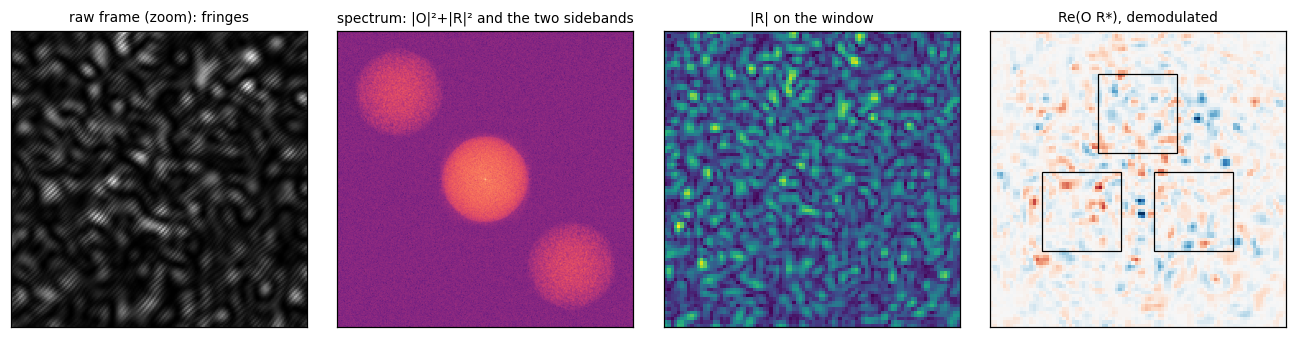

correlation of fringe-matched and demodulated scores over 64 reads, per detector: 0.9937, 0.9958, 0.9967


In [2]:
bench = ref.Bench(seed=0)
det = ref.Detectors([(13, 33), (43, 16), (43, 50)], size=24)               # LEFT, RIGHT, ATTACK
rng = np.random.default_rng(0)
E_random = 0.8 * np.exp(2j * np.pi * rng.random((ref.NE, ref.NE)))
frame = bench.frame(rng.uniform(0, np.pi, (1, tw.NC, tw.NC)), E_random)[0]
d = ref.demodulate(frame)

c, z = ref.NU // 2, 90
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
ax[0].imshow(frame[c - z:c + z, c - z:c + z], cmap="gray"); ax[0].set_title("raw frame (zoom): fringes")
ax[1].imshow(np.log10(np.abs(np.fft.fftshift(np.fft.fft2(frame)))**2 + 1), cmap="magma")
ax[1].set_title("spectrum: |O|²+|R|² and the two sidebands")
ax[2].imshow(np.abs(ref.MODEL.forward(E_random)[ref.W90, ref.W90]), cmap="viridis"); ax[2].set_title("|R| on the window")
v = np.abs(np.real(d[ref.W90, ref.W90])).max()
ax[3].imshow(np.real(d[ref.W90, ref.W90]), cmap="RdBu_r", vmin=-v, vmax=v); ax[3].set_title("Re(O R*), demodulated")
for k, (r, cc) in enumerate(det.corners):
    ax[3].add_patch(Rectangle((cc - 0.5, r - 0.5), det.size, det.size, fill=False, color="k", lw=0.8))
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

raw, demod = bench.read(rng.uniform(0, np.pi, (64, tw.NC, tw.NC)), E_random, det)
print("correlation of fringe-matched and demodulated scores over 64 reads, per detector:",
      ", ".join(f"{np.corrcoef(raw[:, k], demod[:, k])[0, 1]:.4f}" for k in range(3)))

## 2 · The reference-arm model

The reference arm bypasses the diffuser, so its adjoint needs only a model of its own free-space path: the
illumination, the SLM cells, a pupil (iris, defocus, aberrations) and a shift onto the camera, described by a few
parameters (SI Eq. S14, `ref.ReferenceArm`). The twin's model differs from its hidden true arm by a defocus error,
small astigmatism and coma and a sub-pixel shift. As on the bench (Fig. S3a), its **model accuracy** is the correlation
between predicted and measured interference $\hat O R^*$ for random reference patterns, against the repeatability of the
measurement. The model is linear in $E$, so the adjoint is checked against the inner product.

In [3]:
E_test = np.exp(2j * np.pi * rng.random((ref.NE, ref.NE)))
R_test = rng.standard_normal((tw.N, tw.N)) + 1j * rng.standard_normal((tw.N, tw.N))
lhs, rhs = np.vdot(ref.MODEL.forward(E_test), R_test), np.vdot(E_test, ref.MODEL.adjoint(R_test))
print(f"adjoint of the reference model: relative error {abs(lhs - rhs) / abs(lhs):.1e}")

x = rng.uniform(0, np.pi, (1, tw.NC, tw.NC))
O_hat = bench.acquire(np.repeat(x, 5, axis=0)).mean(0)          # the object field, flat reference, five reads
accuracy, repeat = [], []
for _ in range(20):
    E = np.exp(2j * np.pi * rng.random((ref.NE, ref.NE))) * rng.uniform(0.3, 1, (ref.NE, ref.NE))
    d1, d2 = ref.demodulate(bench.frame(np.repeat(x, 2, axis=0), E))[:, ref.W90, ref.W90]
    predicted = (O_hat * np.conj(ref.MODEL.forward(E)))[ref.W90, ref.W90]
    accuracy.append(tw.corr(predicted, d1)); repeat.append(tw.corr(d1, d2))
print(f"reference model accuracy {np.mean(accuracy):.3f} against a repeatability of {np.mean(repeat):.3f} "
      f"(20 random references; bench: 0.85 against 0.96)")

adjoint of the reference model: relative error 4.2e-15


reference model accuracy 0.973 against a repeatability of 0.996 (20 random references; bench: 0.85 against 0.96)


## 3 · VizDoom *Basic*

A Cacodemon floats somewhere on the opposite wall; the player strafes left or right and shoots.

* **Frames and labels.** A noisy oracle plays (mostly the oracle's action, sometimes random ones); every frame with the
  monster is stored with the oracle's action: ATTACK if the monster is within 3.5 px of the centre, else move toward it.
  Near-duplicate frames are dropped and the episodes are split into training, validation and test sets (80/10/10).
* **Encoding** (a fixed colour projection and pooling, no learned features): the 32 rows where the monster appears are
  projected on "magenta" ($R + B - 2G$), pooled in 1 × 5 blocks to $32\times32$ values $v$, and written as phase
  $\varphi = \pi v/255$ on the object cells.

The frames are cached in `vizdoom_basic.npz`; if the file is missing, VizDoom generates it (a few minutes).

9996 frames; training / validation / test = 7824 / 1019 / 1153; LEFT / RIGHT / ATTACK = [4829, 4207, 960]


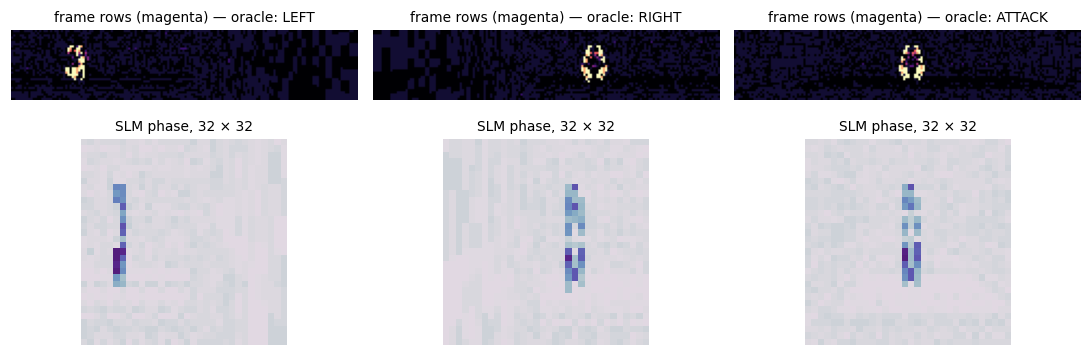

In [4]:
ACTIONS = ["LEFT", "RIGHT", "ATTACK"]


def make_game(scenario):
    game = vzd.DoomGame()
    game.load_config(os.path.join(vzd.scenarios_path, scenario + ".cfg"))
    game.set_screen_resolution(vzd.ScreenResolution.RES_160X120)
    game.set_screen_format(vzd.ScreenFormat.RGB24)
    game.set_labels_buffer_enabled(True)
    game.set_render_hud(False); game.set_render_crosshair(False); game.set_render_weapon(False)
    game.set_window_visible(False)
    game.add_available_game_variable(vzd.GameVariable.KILLCOUNT)
    game.init()
    return game


def collect(scenario, oracle, to_band, n_frames, rng):
    # a noisy oracle plays; frames the oracle can label are stored with its action
    game, bands, labels, episodes, ep = make_game(scenario), [], [], [], 0
    while len(labels) < n_frames:
        game.set_seed(ep); game.new_episode()
        held, left = 0, 0
        while not game.is_episode_finished():
            state = game.get_state()
            label = oracle(state)
            if left > 0:
                action, left = held, left - 1
            elif rng.random() < 0.1:
                held = int(rng.integers(3)); action, left = held, int(rng.integers(2, 8))
            elif label is not None and rng.random() < 0.7:
                action = label
            else:
                action = int(rng.integers(3))
            if label is not None:
                bands.append(to_band(state.screen_buffer)); labels.append(label); episodes.append(ep)
            game.make_action(np.eye(3, dtype=int)[action].tolist(), 4)
        ep += 1
    game.close()
    return np.array(bands), np.array(labels), np.array(episodes)


def make_dataset(path, bands, labels, episodes, rng, cap=False):
    # drop near-duplicates within an episode, optionally cap the classes, split the episodes 80/10/10
    cells = bands.reshape(len(bands), 32, 32, 5).mean(-1)
    keep, last = [], None
    for i in range(len(labels)):
        if last is None or episodes[i] != episodes[last] or np.mean((cells[i] - cells[last])**2) >= 4.0:
            keep.append(i); last = i
    keep = np.array(keep)
    if cap:
        n = 3 * np.bincount(labels[keep]).min()
        keep = np.sort(np.concatenate([rng.permutation(keep[labels[keep] == c])[:n] for c in range(3)]))
    order = rng.permutation(np.unique(episodes[keep]))
    part = {e: 0 if k < 0.8 * len(order) else (1 if k < 0.9 * len(order) else 2) for k, e in enumerate(order)}
    np.savez_compressed(path, band=bands[keep], labels=labels[keep], split=[part[e] for e in episodes[keep]],
                        episode=episodes[keep])


def basic_band(rgb):
    b = rgb[48:80].astype(int)
    return np.clip(6 * (b[..., 0] + b[..., 2] - 2 * b[..., 1]), 0, 255).astype(np.uint8)


def basic_error(state):
    # horizontal distance (px) of the monster from the centre of the screen, None if it is not visible
    for label in state.labels:
        if label.object_name == "Cacodemon":
            return label.x + label.width / 2 - 80
    return None


def basic_oracle(state):
    e = basic_error(state)
    return None if e is None else (2 if abs(e) <= 3.5 else (0 if e < 0 else 1))


basic_phase = lambda bands: np.pi * bands.reshape(bands.shape[:-1] + (32, 5)).mean(-1) / 255

path = os.path.join(DATA, "vizdoom_basic.npz")
if not os.path.exists(path):
    make_dataset(path, *collect("basic", basic_oracle, basic_band, 12000, np.random.default_rng(0)), np.random.default_rng(0))
data = np.load(path)
basic = dict(phi=basic_phase(data["band"]), y=data["labels"].astype(int), split=data["split"], band=data["band"],
             det=ref.Detectors(det.corners, size=24, soft=True))              # the bench's soft detectors of this run
TRAIN, VAL, TEST = (np.nonzero(basic["split"] == k)[0] for k in range(3))
print(f"{len(basic['y'])} frames; training / validation / test = {len(TRAIN)} / {len(VAL)} / {len(TEST)}; "
      f"LEFT / RIGHT / ATTACK = {np.bincount(basic['y']).tolist()}")

fig, axs = plt.subplots(2, 3, figsize=(10, 3.4), gridspec_kw=dict(height_ratios=[1, 1.6]))
for a in range(3):
    i = TRAIN[np.nonzero(basic["y"][TRAIN] == a)[0][10]]
    axs[0, a].imshow(basic["band"][i], cmap="magma"); axs[0, a].set_title(f"frame rows (magenta) — oracle: {ACTIONS[a]}")
    axs[1, a].imshow(basic["phi"][i], cmap="twilight", vmin=0, vmax=2 * np.pi); axs[1, a].set_title("SLM phase, 32 × 32")
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

### Offline training

Every frame is written once with the flat reference and its field $\hat O_n$ is stored at the detector pixels: one SLM
pattern per sample, however many training steps follow. $E$ ($100\times100$, $|E|\le1$) is then trained in software on the
stored fields (`ref.train_reference`): the scores $s_c = \sum_{M_c}\mathrm{Re}(\hat O R^*)$ are linear in $E$, the loss is
the class-weighted cross-entropy plus a total-variation penalty, and the gradient $\partial L/\partial E^* =
T_R^{\mathrm H}\{\tfrac12\sum_n \hat O_n\sum_c g_{nc}M_c\}$ goes through the reference model only (30 epochs).

**Basic is read by demodulation**, as in the article (main Fig. 3c, Supplementary Note 4B): the plain reference, trained
with the recipe above (the epoch with the best validation accuracy in the model is kept), is written once, every test
frame is read once, and the action is the brightest detector of the demodulated field $d = OR^*$, with no offset
correction. As in that bench run (2026-10-14), the three detectors are the bench's soft super-Gaussian windows centred on
the same 24-pixel boxes, $M_c = \exp[-((\Delta y/s)^8 + (\Delta x/s)^8)]$ with $s = 16.2$ pixels; their smooth edges let
light just outside a box still move its score. The fringe-matched read of the same frames is shown next to it. *Defend the Center* (section 4) is read
from the raw frame.

In [5]:
def train(sc, **recipe):
    # acquire the fields once with the flat reference, then train E offline on them
    t0 = time.time()
    split = [np.nonzero(sc["split"] == k)[0] for k in range(3)]
    sc["O"] = bench.acquire(sc["phi"], detectors=sc["det"])
    sc["E"], sc["history"] = ref.train_reference(sc["O"][split[0]], sc["y"][split[0]], sc["O"][split[1]], sc["y"][split[1]],
                                                 sc["det"], **recipe)
    print(f"acquired {len(sc['y']):,} fields and trained E in {time.time() - t0:.0f} s; best validation score in the "
          f"model {sc['history'][:, 1].max():.3f}")


def test(sc, idx, E):
    # read every test frame once with E; scores, decisions and accuracy of both reads of the same frames
    y = sc["y"][idx]
    out = {}
    for name, s in zip(("raw", "demod"), bench.read(sc["phi"][idx], E, sc["det"])):
        pred = s.argmax(1)
        out[name] = dict(s=s, pred=pred, acc=np.mean(pred == y), bal=ref.balanced_accuracy(pred, y),
                         recall=np.array([np.mean(pred[y == k] == k) for k in range(3)]))
    return out


train(basic)
basic_test = test(basic, TEST, basic["E"])
for name, label in (("demod", "demodulated"), ("raw", "fringe-matched (raw frame)")):
    print(f"{label:27s} test accuracy {basic_test[name]['acc']:.3f} "
          f"(recall LEFT / RIGHT / ATTACK {' / '.join(f'{v:.2f}' for v in basic_test[name]['recall'])})")
print(f"flat reference: {np.mean(bench.read(basic['phi'][TEST], ref.FLAT, basic['det'])[1].argmax(1) == basic['y'][TEST]):.3f}")

acquired 9,996 fields and trained E in 359 s; best validation score in the model 0.974


demodulated                 test accuracy 0.889 (recall LEFT / RIGHT / ATTACK 1.00 / 0.75 / 1.00)
fringe-matched (raw frame)  test accuracy 0.903 (recall LEFT / RIGHT / ATTACK 1.00 / 0.78 / 1.00)


flat reference: 0.096


**Agreement of the two reads** (cf. Fig. S3b): the scores of the same test frames, each z-scored, and how often the two
reads take the same decision. **Digital baseline:** a linear classifier on the same encoded inputs, as on the bench:
class-balanced logistic regression on the $32\times32$ input values (scaled to 0–1), with the L2 strength
$C \in \{0.01, 0.1, 1, 10\}$ chosen on the validation frames.

fringe-matched vs demodulated scores: r = 0.9999, 0.9999, 0.9999; same decision on 98.6 % of the test frames; digital linear classifier 0.998


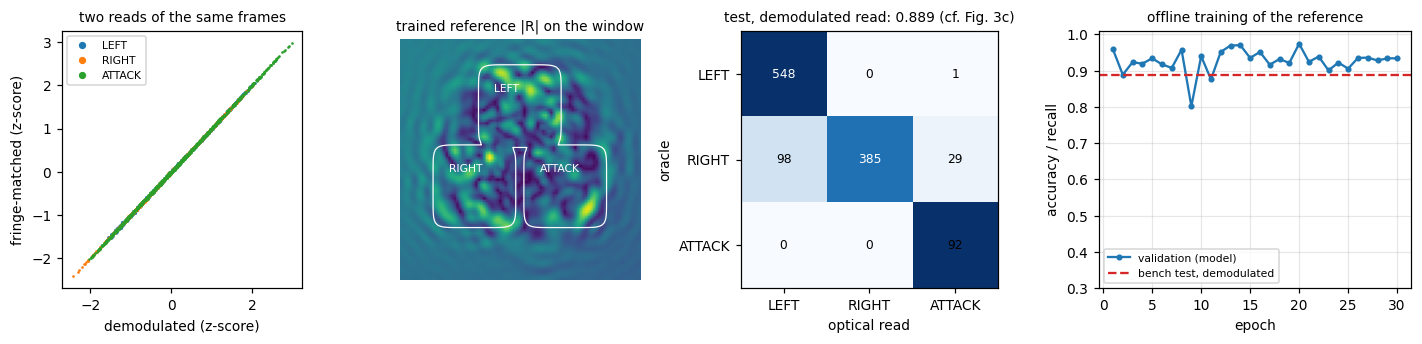

In [6]:
import scipy.optimize


def logistic_regression(X, y, C):
    # class-balanced multinomial logistic regression: sum_n w_n CE_n + |W|^2 / (2C), intercept not penalised
    n, f = X.shape
    w = (len(y) / (3 * np.bincount(y, minlength=3)))[y]

    def loss(p):
        W, b = p[:3 * f].reshape(f, 3), p[3 * f:]
        z = X @ W + b
        z = z - z.max(1, keepdims=True)
        P = np.exp(z); P /= P.sum(1, keepdims=True)
        G = w[:, None] * (P - np.eye(3)[y])
        L = -np.sum(w * np.log(P[np.arange(n), y] + 1e-300)) + np.sum(W * W) / (2 * C)
        return L, np.concatenate([(X.T @ G + W / C).ravel(), G.sum(0)])
    p = scipy.optimize.minimize(loss, np.zeros(3 * f + 3), jac=True, method="L-BFGS-B", options=dict(maxiter=3000)).x
    W, b = p[:3 * f].reshape(f, 3), p[3 * f:]
    return lambda X_new: (X_new @ W + b).argmax(1)


def linear_classifier(X, y, X_val, y_val):
    # the bench's digital linear baseline: C chosen on the validation frames
    models = [logistic_regression(X, y, C) for C in (0.01, 0.1, 1.0, 10.0)]
    return max(models, key=lambda m: np.mean(m(X_val) == y_val))


features = lambda phi: phi.reshape(len(phi), -1) / np.pi                     # the encoded values, 0..1
basic_linear = linear_classifier(features(basic["phi"][TRAIN]), basic["y"][TRAIN],
                                 features(basic["phi"][VAL]), basic["y"][VAL])
acc_linear = np.mean(basic_linear(features(basic["phi"][TEST])) == basic["y"][TEST])

z = lambda s: (s - s.mean(0)) / s.std(0)
r = [np.corrcoef(basic_test["raw"]["s"][:, k], basic_test["demod"]["s"][:, k])[0, 1] for k in range(3)]
same = np.mean(basic_test["raw"]["pred"] == basic_test["demod"]["pred"])
print(f"fringe-matched vs demodulated scores: r = {', '.join(f'{v:.4f}' for v in r)}; same decision on {100 * same:.1f} % "
      f"of the test frames; digital linear classifier {acc_linear:.3f}")

fig, axs = plt.subplots(1, 4, figsize=(13, 3.2), gridspec_kw=dict(width_ratios=[1, 1, 1.1, 1.3]))
for k in range(3):
    axs[0].plot(z(basic_test["demod"]["s"])[:, k], z(basic_test["raw"]["s"])[:, k], ".", ms=1.5, label=ACTIONS[k])
axs[0].set_xlabel("demodulated (z-score)"); axs[0].set_ylabel("fringe-matched (z-score)"); axs[0].legend(fontsize=7, markerscale=5)
axs[0].set_title("two reads of the same frames")
axs[1].imshow(np.abs(bench._ref.forward(ref.slm_response(basic["E"]))[ref.W90, ref.W90]), cmap="viridis")
axs[1].contour(basic["det"].window.max(0), levels=[0.5], colors="w", linewidths=0.8)
for k, (rr, cc) in enumerate(det.corners):
    axs[1].text(cc + 2, rr + 6, ACTIONS[k], color="w", fontsize=7)
axs[1].set_title("trained reference |R| on the window"); axs[1].axis("off")
cm = np.zeros((3, 3))
for t, p in zip(basic["y"][TEST], basic_test["demod"]["pred"]): cm[t, p] += 1
axs[2].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3): axs[2].text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8, color="w" if cm[i, j] > cm.max() / 2 else "k")
axs[2].set_xticks(range(3)); axs[2].set_xticklabels(ACTIONS); axs[2].set_yticks(range(3)); axs[2].set_yticklabels(ACTIONS)
axs[2].set_xlabel("optical read"); axs[2].set_ylabel("oracle")
axs[2].set_title(f"test, demodulated read: {basic_test['demod']['acc']:.3f} (cf. Fig. 3c)")
axs[3].plot(range(1, len(basic["history"]) + 1), basic["history"][:, 1], "o-", ms=3, label="validation (model)")
axs[3].axhline(basic_test["demod"]["acc"], color="C3", ls="--", label="bench test, demodulated")
axs[3].set_xlabel("epoch"); axs[3].set_ylabel("accuracy / recall"); axs[3].set_ylim(0.3, 1.01); axs[3].grid(alpha=0.3)
axs[3].legend(fontsize=7); axs[3].set_title("offline training of the reference")
plt.tight_layout(); plt.show()

### Closed loop

The bench plays: every game frame is encoded, written on the object arm, read **once** with the trained reference
(demodulated read, plain reference), and the brightest detector is the action (four game tics per action). 100
episodes on seeds never used for the data; an episode is won when the monster dies before the timeout. The oracle and a
random policy play the same seeds. A GIF shows one episode as the bench plays it.

policy              won  steps to kill
optical (bench)   98/100           7.22
oracle           100/100           7.42
random            50/100          30.98
paired difference optical - oracle: -0.14 ± 0.07 steps (on 98 episodes both won)


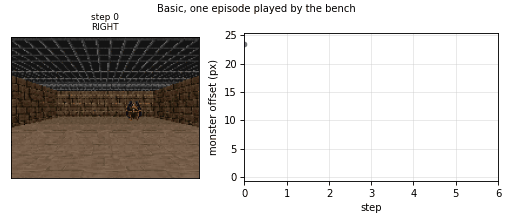

In [7]:
def optical_policy(sc, encode, read="raw"):
    # one bench read per game frame with the scenario's E and detectors; the brightest detector of the chosen read
    k = 0 if read == "raw" else 1
    return lambda state: int(np.argmax(bench.read(encode(state.screen_buffer), sc["E"], sc["det"])[k][0]))


def play(scenario, policy, seeds, record=None):
    # kills and steps per episode; with record(state) -> value, also the frames, actions and values of the first episode
    game, kills, steps, frames = make_game(scenario), [], [], []
    for s in seeds:
        game.set_seed(int(s)); game.new_episode()
        n = 0
        while not game.is_episode_finished():
            state = game.get_state()
            action = policy(state)
            if record and s == seeds[0]:
                frames.append((state.screen_buffer.copy(), action, record(state)))
            game.make_action(np.eye(3, dtype=int)[action].tolist(), 4)
            n += 1
        kills.append(game.get_game_variable(vzd.GameVariable.KILLCOUNT)); steps.append(n)
    game.close()
    return dict(kills=np.array(kills), steps=np.array(steps), frames=frames)


rng_play = np.random.default_rng(0)
seeds = np.arange(1_000_000, 1_000_100)
basic_encode = lambda rgb: basic_phase(basic_band(rgb)[None])
offset_px = lambda st: abs(basic_error(st)) if basic_error(st) is not None else np.nan
policies = {"optical (bench)": optical_policy(basic, basic_encode, read="demod"),
            "oracle": lambda st: basic_oracle(st) if basic_oracle(st) is not None else int(rng_play.integers(3)),
            "random": lambda st: int(rng_play.integers(3))}
basic_loop = {name: play("basic", pol, seeds, record=offset_px if name == "optical (bench)" else None)
              for name, pol in policies.items()}
won = {name: r["kills"] > 0 for name, r in basic_loop.items()}
both = won["optical (bench)"] & won["oracle"]
diff = basic_loop["optical (bench)"]["steps"][both] - basic_loop["oracle"]["steps"][both]
print(f"{'policy':16s} {'won':>6s} {'steps to kill':>14s}")
for name, r in basic_loop.items():
    print(f"{name:16s} {won[name].sum():3d}/100 {r['steps'][won[name]].mean():14.2f}")
print(f"paired difference optical - oracle: {diff.mean():+.2f} ± {diff.std() / np.sqrt(len(diff)):.2f} steps "
      f"(on {both.sum()} episodes both won)")

ep = basic_loop["optical (bench)"]["frames"]
tw.save_gif("gifs/vizdoom_basic_episode.gif", [f for f, _, _ in ep], [v for _, _, v in ep], "monster offset (px)",
            "Basic, one episode played by the bench", xlabel="step", captions=[ACTIONS[a] for _, a, _ in ep], fps=3)
display(Image(filename="gifs/vizdoom_basic_episode.gif"))

## 4 · *Defend the Center*

Monsters approach from all sides; the player turns left or right and shoots. The oracle turns toward the largest
monster in view, shoots when it is centred, and turns left when nothing is in view.

* **Encoding** (fixed, no learned features): rows 44–75 projected on fixed colour weights that separate the monsters from
  the walls, then the maximum of each 1 × 5 block and of each column, written to all 32 rows: the horizontal position of
  the monsters, which decides the action, is what reaches the SLM.
* **Data**: as for *Basic*, with the classes capped (cached in `vizdoom_defend_the_center.npz`).

The reference is trained offline exactly as for *Basic*, and the bench plays with the **plain** reference: one
raw-frame read per step with the fringe-matched masks, the brightest detector is the action, with no offset correction
and no lean toward one action (the bench's plain raw-frame run, 7.87 ± 0.93 kills). The bench then plays 30 episodes on
the bench's seeds (1,000,000–1,000,029); the score is the number of kills per episode (mean ± s.e.m.), against the
oracle, a digital linear classifier on the same inputs and random actions, none of them with a lean (Fig. 3d).

In [8]:
LDA, LO, HI = np.array([0.18311, -0.57792, 0.23897]), -9.1941, 14.2908
TARGETS = ("MarineChainsawVzd", "Demon")


def dtc_band(rgb):
    p = rgb[44:76].astype(float) @ LDA
    return np.clip(np.round(255 * (p - LO) / (HI - LO)), 0, 255).astype(np.uint8)


def dtc_oracle(state):
    best = None
    for label in state.labels:
        if label.object_name in TARGETS and label.width >= 1 and label.height >= 0.8 * label.width \
                and (best is None or label.height > best.height):
            best = label
    if best is None:
        return 0
    e = best.x + best.width / 2 - 80
    return 2 if abs(e) <= max(1, 0.5 * best.width) else (0 if e < 0 else 1)


def dtc_phase(bands):
    column = bands.reshape(bands.shape[:-1] + (32, 5)).max(-1).max(-2)                 # one value per column
    return np.pi * np.repeat(column[..., None, :], 32, axis=-2) / 255


path = os.path.join(DATA, "vizdoom_defend_the_center.npz")
if not os.path.exists(path):
    make_dataset(path, *collect("defend_the_center", dtc_oracle, dtc_band, 16000, np.random.default_rng(0)),
                 np.random.default_rng(0), cap=True)
data = np.load(path)
dtc = dict(phi=dtc_phase(data["band"]), y=data["labels"].astype(int), split=data["split"], band=data["band"],
           det=det)                                                            # hard 24 px boxes, as in that run
D_TRAIN, D_VAL, D_TEST = (np.nonzero(dtc["split"] == k)[0] for k in range(3))
print(f"{len(dtc['y'])} frames; training / validation / test = {len(D_TRAIN)} / {len(D_VAL)} / {len(D_TEST)}")

train(dtc)
dtc_test = test(dtc, D_TEST, dtc["E"])                                   # plain reference
dtc_linear = linear_classifier(features(dtc["phi"][D_TRAIN]), dtc["y"][D_TRAIN], features(dtc["phi"][D_VAL]), dtc["y"][D_VAL])
for name, label in (("raw", "fringe-matched (raw frame)"), ("demod", "demodulated")):
    print(f"{label:27s} test balanced accuracy {dtc_test[name]['bal']:.3f} (plain reference, no offset correction)")
print(f"digital linear classifier: balanced accuracy "
      f"{ref.balanced_accuracy(dtc_linear(features(dtc['phi'][D_TEST])), dtc['y'][D_TEST]):.3f}")

10000 frames; training / validation / test = 8059 / 833 / 1108


acquired 10,000 fields and trained E in 351 s; best validation score in the model 0.819


fringe-matched (raw frame)  test balanced accuracy 0.793 (plain reference, no offset correction)
demodulated                 test balanced accuracy 0.799 (plain reference, no offset correction)
digital linear classifier: balanced accuracy 0.790


policy                         kills per episode (30 unseen seeds, no lean)
optical (bench)                 2.53 ± 0.34
oracle                         15.40 ± 1.04
digital linear                  3.53 ± 0.57
random                          1.63 ± 0.24


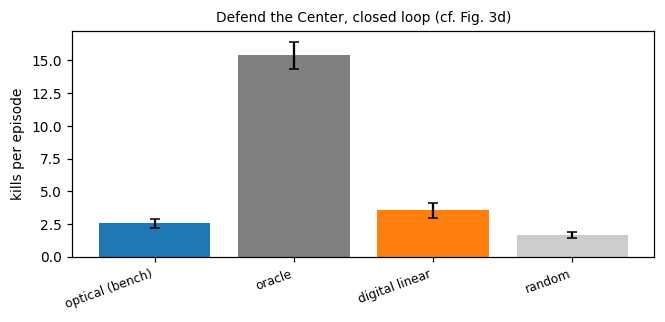

'gifs/vizdoom_defend_the_center_episode.gif'

In [9]:
dtc_encode = lambda rgb: dtc_phase(dtc_band(rgb)[None])
kills = lambda st: st.game_variables[-1]                                  # KILLCOUNT, added last in make_game
seeds = np.arange(1_000_000, 1_000_030)
policies = {"optical (bench)": optical_policy(dtc, dtc_encode),         # plain reference, raw-frame read, no lean
            "oracle": dtc_oracle,
            "digital linear": lambda st: int(dtc_linear(features(dtc_encode(st.screen_buffer)))[0]),
            "random": lambda st: int(rng_play.integers(3))}
dtc_loop = {name: play("defend_the_center", pol, seeds, record=kills if name == "optical (bench)" else None)
            for name, pol in policies.items()}
print(f"{'policy':30s} kills per episode (30 unseen seeds, no lean)")
for name, r in dtc_loop.items():
    print(f"{name:30s} {r['kills'].mean():5.2f} ± {r['kills'].std() / np.sqrt(len(r['kills'])):.2f}")

fig, ax = plt.subplots(figsize=(6, 3))
names = list(dtc_loop)
ax.bar(range(len(names)), [dtc_loop[n]["kills"].mean() for n in names],
       yerr=[dtc_loop[n]["kills"].std() / np.sqrt(len(seeds)) for n in names], color=["C0", "0.5", "C1", "0.8"], capsize=3)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("kills per episode"); ax.set_title("Defend the Center, closed loop (cf. Fig. 3d)")
plt.tight_layout(); plt.show()

ep = dtc_loop["optical (bench)"]["frames"]
tw.save_gif("gifs/vizdoom_defend_the_center_episode.gif", [f for f, _, _ in ep], [k for _, _, k in ep], "kills",
            "Defend the Center, one episode played by the bench", xlabel="step",
            captions=[ACTIONS[a] for _, a, _ in ep], fps=10)

One episode of *Defend the Center* played by the bench (linked GIF, `gifs/vizdoom_defend_the_center_episode.gif`):

![Defend the Center](gifs/vizdoom_defend_the_center_episode.gif)

## Summary: the twin next to the bench

The bench values are those of the article (main text and Supplementary Note 4): *Basic* with the plain reference read
by demodulation (run of 2026-10-14), *Defend the Center* with the plain reference read from the raw frame (run of
2026-10-25). All policies play without a lean or offset correction.

In [10]:
sem = lambda k: np.std(k, ddof=1) / np.sqrt(len(k))
rows = [
    ("reference-model accuracy (check probes)", f"{np.mean(accuracy):.3f}", "0.854"),
    ("Basic: test, demodulated read", f"{basic_test['demod']['acc']:.3f}", "0.987"),
    ("Basic: recall LEFT / RIGHT / ATTACK", " / ".join(f"{v:.2f}" for v in basic_test["demod"]["recall"]), "1.00 / 0.98 / 0.98"),
    ("Basic: closed loop, episodes won", f"{won['optical (bench)'].sum()}/100", "100/100"),
    ("Basic: closed loop, steps optical - oracle", f"{diff.mean():+.2f}", "+0.09"),
    ("Defend the Center: test, raw-frame read, plain E", f"{dtc_test['raw']['acc']:.3f}", "0.718"),
]
for name, b in [("optical, plain, raw frame", "7.87 ± 0.93"), ("digital linear", "3.50 ± 0.70"),
                ("random", "1.37 ± 0.20"), ("oracle", "12.03 ± 0.74")]:
    k = dtc_loop["optical (bench)" if name.startswith("optical") else name]["kills"]
    rows.append((f"Defend the Center: kills, {name}", f"{k.mean():.2f} ± {sem(k):.2f}", b))
print(f"{'':48s} {'twin':>12s} {'bench':>12s}")
for name, t, b in rows:
    print(f"{name:48s} {t:>12s} {b:>12s}")
print(f"\nbench reads in the twin: {bench.reads:,}; diffuser probes: 0; runtime {time.time() - T_START:.0f} s")

                                                         twin        bench
reference-model accuracy (check probes)                 0.973        0.854
Basic: test, demodulated read                           0.889        0.987
Basic: recall LEFT / RIGHT / ATTACK              1.00 / 0.75 / 1.00 1.00 / 0.98 / 0.98
Basic: closed loop, episodes won                       98/100      100/100
Basic: closed loop, steps optical - oracle              -0.14        +0.09
Defend the Center: test, raw-frame read, plain E        0.765        0.718
Defend the Center: kills, optical, plain, raw frame  2.53 ± 0.35  7.87 ± 0.93
Defend the Center: kills, digital linear          3.53 ± 0.58  3.50 ± 0.70
Defend the Center: kills, random                  1.63 ± 0.24  1.37 ± 0.20
Defend the Center: kills, oracle                 15.40 ± 1.06 12.03 ± 0.74

bench reads in the twin: 27,033; diffuser probes: 0; runtime 962 s


**Take-aways.** The diffuser is never modelled and never probed: the object fields are measured once with
a flat reference, and the reference is trained offline through a model of its own free-space path. In *Basic*, the plain
reference read by demodulation with the bench's soft detectors classifies test frames with 0.889 accuracy and recalls
every action (1.00 / 0.75 / 1.00; bench: 0.987, 1.00 / 0.98 / 0.98), and in closed loop it wins 98 of 100 unseen
episodes as fast as the oracle (−0.1 steps; bench: 100 of 100, +0.1 steps). The fringe-matched read of the raw frame
gives the same scores (r ≥ 0.9999) and the same decision on 98.6 % of the frames. In *Defend the Center* the plain
reference, read from the raw frame with no offset correction and no lean, kills 2.5 ± 0.3 enemies per episode, level with
the bench's digital linear classifier (3.5) and above random actions (1.6). On the bench the same recipe gave 7.9 ± 0.9
kills in one session and 3.9 ± 0.6 in another: the kills follow the left/right balance of the detector offsets, which
changes between sessions. The twin's oracle (VizDoom 1.3.1 on this computer) plays better than the bench's on the same
seeds (15.4 against 12.0 kills).